# Loops in Python

A **loop** repeats a block of code. Loops let one short program process a list of 10 items or of 10 million items.

**After this lesson you can:**

1. Iterate over collections with `for`.
2. Use `range`, `enumerate` and `zip`.
3. Repeat until a condition changes with `while`.
4. Control loops with `break`, `continue` and `else`.

## 1. The `for` Loop

A `for` loop takes each item of an **iterable** (a list, a string, a range, a file, ...) in turn and runs the block once for each item.

| Helper | Gives you | Example |
| :--- | :--- | :--- |
| `range(start, stop, step)` | integers, `stop` excluded | `range(0, 10, 2)` → 0, 2, 4, 6, 8 |
| `enumerate(items)` | `(index, item)` pairs | numbered output |
| `zip(a, b)` | items of several iterables side by side | pair names with scores |

In [1]:
cities = ["Ankara", "Izmir", "Bursa"]
populations = [5_803_482, 4_479_525, 3_214_571]     # 2023 census figures (TÜİK)

for city in cities:
    print(city)

print("---")
for i, city in enumerate(cities, start=1):
    print(f"{i}. {city}")

print("---")
total = 0
for city, pop in zip(cities, populations):
    total += pop
    print(f"{city:<7} {pop:>10,}")
print(f"{'Total':<7} {total:>10,}")

Ankara
Izmir
Bursa
---
1. Ankara
2. Izmir
3. Bursa
---
Ankara   5,803,482
Izmir    4,479,525
Bursa    3,214,571
Total   13,497,578


## 2. The `while` Loop

A `while` loop repeats as long as its condition is true. Use it when you do not know the number of repetitions in advance. Make sure that the loop changes the condition; otherwise it never stops.

The example computes how many years an investment needs to double at 7% interest per year.

In [2]:
balance, rate, years = 1_000.0, 0.07, 0
history = [balance]
while balance < 2_000:
    balance *= 1 + rate
    years += 1
    history.append(balance)
print(f"The money doubles after {years} years: {balance:,.2f}")
print(f"Rule of 72 estimate: {72 / (rate * 100):.1f} years")

The money doubles after 11 years: 2,104.85
Rule of 72 estimate: 10.3 years


## 3. `break`, `continue` and `else`

- `break` stops the loop immediately.
- `continue` skips the rest of the current iteration and starts the next one.
- The `else` block of a loop runs only if the loop ended **without** `break`. It is useful for search loops.

In [3]:
readings = [21.0, 22.5, None, 23.1, 99.0, 22.8]

clean = []
for r in readings:
    if r is None:
        continue                      # skip missing values
    if r > 60:
        print(f"Sensor error: {r} -> stop reading")
        break                         # stop on an impossible value
    clean.append(r)
print("Clean readings:", clean)

def first_negative(numbers):
    for n in numbers:
        if n < 0:
            print("found", n)
            break
    else:                             # runs only when no break happened
        print("no negative number")

first_negative([3, 5, -2, 8])
first_negative([3, 5, 8])

Sensor error: 99.0 -> stop reading
Clean readings: [21.0, 22.5, 23.1]
found -2
no negative number


## 4. Nested Loops and Their Cost

A loop inside a loop runs its inner block $n \times m$ times. The example builds a multiplication table. Nested loops are simple, but the cost grows fast: two nested loops over $n$ items do $n^2$ steps.

In [4]:
for i in range(1, 6):
    row = ""
    for j in range(1, 6):
        row += f"{i * j:4}"
    print(row)

   1   2   3   4   5
   2   4   6   8  10
   3   6   9  12  15
   4   8  12  16  20
   5  10  15  20  25


## 5. Visualising a Loop: Compound Growth

The `while` loop from Section 2 stored the balance of each year in `history`. The plot compares compound growth with simple (linear) growth.

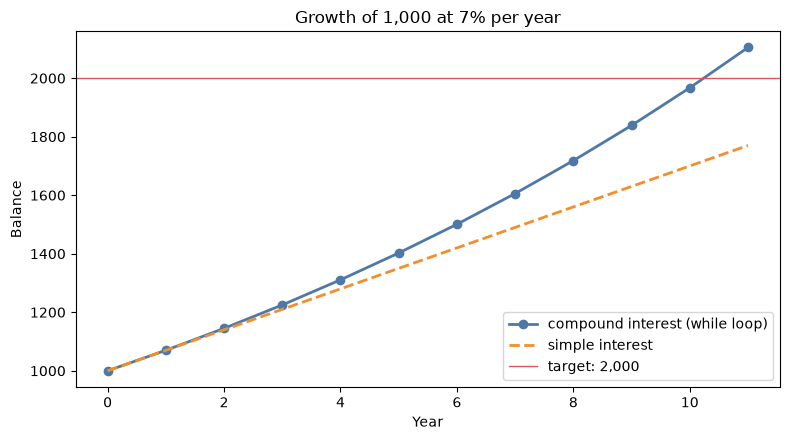

After 11 years: compound 2,105 vs simple 1,770


In [5]:
import matplotlib.pyplot as plt

years_axis = list(range(len(history)))
simple = [1_000 * (1 + rate * y) for y in years_axis]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(years_axis, history, marker="o", lw=2, color="#4E79A7", label="compound interest (while loop)")
ax.plot(years_axis, simple, ls="--", lw=2, color="#F28E2B", label="simple interest")
ax.axhline(2_000, color="#E15759", lw=1, label="target: 2,000")
ax.set(title="Growth of 1,000 at 7% per year", xlabel="Year", ylabel="Balance")
ax.legend()
plt.tight_layout()
plt.show()
print(f"After {years} years: compound {history[-1]:,.0f} vs simple {simple[-1]:,.0f}")

*Insight: Prefer `for` over `while` when you iterate over a collection: `for` cannot run forever and does not need a manual counter. In data work, many loops later become vectorised NumPy or pandas operations (M08), which run 10–100 times faster.*

## Real-World Use Case or Analogy

- A **`for` loop** is a cashier who scans every item in the basket, one at a time, until the basket is empty.
- A **`while` loop** is a person who fills a bucket with a cup until the bucket is full; nobody counts the cups in advance.
- **`break`** is the cashier who stops when the card is declined; **`continue`** is the cashier who skips an item that has no barcode.

Data pipelines use the same pattern: a loop reads records from a file or a message queue, skips bad records (`continue`) and stops on a fatal error (`break`).